**Cell 1: Imports and settings**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../data/GaltonFamilies.csv"   # relative to notebooks/; on Colab, upload the CSV and use "GaltonFamilies.csv"
PARENT_COLUMN = "mother"           # "mother" or "father"
PARENT_LABEL = PARENT_COLUMN.capitalize() + "s"   # "Mothers" or "Fathers", used in output
TOLERANCE = 1e-6                   # stop when log-likelihood changes less than this
MAX_ITERATIONS = 500

In [ ]:
def load_heights(path, parent_column):
    """Return pooled heights plus the hidden true labels (1 = child, 0 = parent)."""
    df = pd.read_csv(path)
    parents = df.drop_duplicates("family")[parent_column].to_numpy()   # one parent per family
    children = df["childHeight"].to_numpy()
    heights = np.concatenate([children, parents])
    true_labels = np.concatenate([np.ones(len(children)), np.zeros(len(parents))])
    return heights, true_labels, children, parents

heights, true_labels, children, parents = load_heights(DATA_PATH, PARENT_COLUMN)
print(f"Children: {len(children)}  mean={children.mean():.2f}  var={children.var():.2f}")
print(f"Parents : {len(parents)}  mean={parents.mean():.2f}  var={parents.var():.2f}")
print(f"Pooled  : {len(heights)} heights (labels hidden from EM)")

Children: 934  mean=66.75  var=12.80
Parents : 205  mean=64.00  var=5.42
Pooled  : 1139 heights (labels hidden from EM)


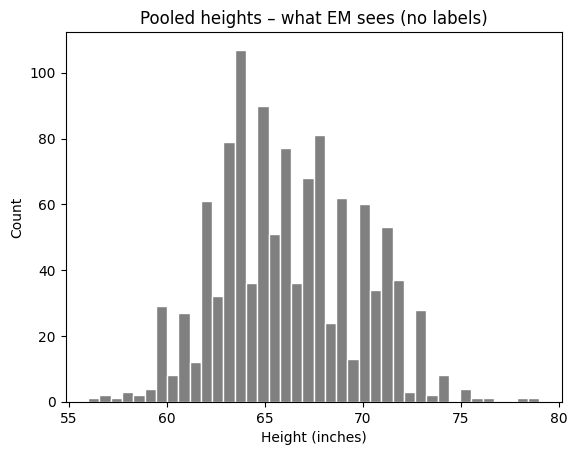

In [ ]:
plt.hist(heights, bins=40, color="grey", edgecolor="white")
plt.title("Pooled heights – what EM sees (no labels)")
plt.xlabel("Height (inches)")
plt.ylabel("Count")
plt.show()

In [ ]:
def gaussian_pdf(x, mean, variance):
    return np.exp(-(x - mean) ** 2 / (2 * variance)) / np.sqrt(2 * np.pi * variance)


def weighted_densities(x, params):
    """Row k holds pi_k * N(x | mu_k, var_k) for every point."""
    return np.vstack([
        params["pi"][k] * gaussian_pdf(x, params["mu"][k], params["var"][k])
        for k in range(len(params["mu"]))
    ])


def log_likelihood(x, params):
    return np.sum(np.log(weighted_densities(x, params).sum(axis=0)))


def e_step(x, params):
    """Responsibilities: probability each point belongs to each component."""
    weighted = weighted_densities(x, params)
    return weighted / weighted.sum(axis=0)


def m_step(x, resp):
    """Re-estimate parameters using responsibilities as soft weights."""
    Nk = resp.sum(axis=1)
    mu = (resp * x).sum(axis=1) / Nk
    var = (resp * (x - mu[:, None]) ** 2).sum(axis=1) / Nk
    pi = Nk / len(x)
    return {"mu": mu, "var": var, "pi": pi}

In [ ]:
def initialize(x):
    return {
        "mu": np.array([np.percentile(x, 75), np.percentile(x, 25)]),   # [children, parents]
        "var": np.array([x.var(), x.var()]),
        "pi": np.array([0.5, 0.5]),
    }

In [ ]:
def record(iteration, params, x):
    return {
        "Iteration": iteration,
        "μ1 (Children)": params["mu"][0], f"μ2 ({PARENT_LABEL})": params["mu"][1],
        "σ1²": params["var"][0], "σ2²": params["var"][1],
        "π1": params["pi"][0], "π2": params["pi"][1],
        "Log-Likelihood": log_likelihood(x, params),
    }


def run_em(x, tol=TOLERANCE, max_iter=MAX_ITERATIONS):
    params = initialize(x)
    history = [record(0, params, x)]
    for it in range(1, max_iter + 1):
        resp = e_step(x, params)
        params = m_step(x, resp)
        history.append(record(it, params, x))
        if abs(history[-1]["Log-Likelihood"] - history[-2]["Log-Likelihood"]) < tol:
            break
    return params, pd.DataFrame(history)


final_params, history = run_em(heights)
print(f"Converged after {history['Iteration'].iloc[-1]} iterations")

Converged after 386 iterations


In [ ]:
pd.set_option("display.float_format", "{:.4f}".format)
history.head(3)

,Iteration,μ1 (Children),μ2 (Mothers),σ1²,σ2²,π1,π2,Log-Likelihood
0,0,69.0000,63.5000,12.5802,12.5802,0.5000,0.5000,-3115.4014
1,1,68.2536,64.3037,9.8201,7.5712,0.4933,0.5067,-3046.1412
2,2,68.3165,64.2587,10.0323,6.9517,0.4913,0.5087,-3044.0230


In [ ]:
history.tail(1)

,Iteration,μ1 (Children),μ2 (Mothers),σ1²,σ2²,π1,π2,Log-Likelihood
386,386,69.7856,64.2993,5.4747,5.7935,0.3559,0.6441,-3035.7484


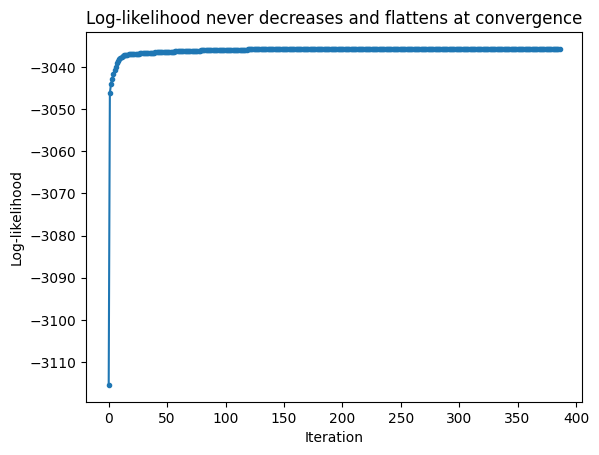

In [ ]:
plt.plot(history["Iteration"], history["Log-Likelihood"], marker=".")
plt.title("Log-likelihood never decreases and flattens at convergence")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.show()

In [ ]:
def classify(height, params):
    resp = e_step(np.array([height], dtype=float), params)[:, 0]
    print(f"Height {height} in")
    print(f"  P(Child  | height) = {resp[0]:.4f}")
    print(f"  P({PARENT_COLUMN.capitalize()} | height) = {resp[1]:.4f}")
    return resp

classify(66.0, final_params)   # replace 66.0 with the coach's height

Height 66.0 in
  P(Child  | height) = 0.1647
  P(Mother | height) = 0.8353


array([0.1646665, 0.8353335])

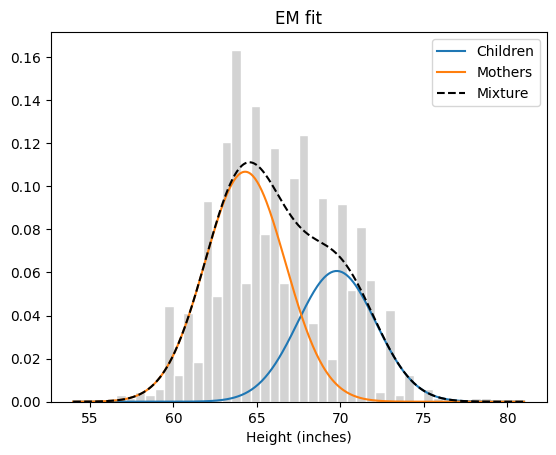

In [ ]:
grid = np.linspace(heights.min() - 2, heights.max() + 2, 400)
plt.hist(heights, bins=40, density=True, color="lightgrey", edgecolor="white")
for k, name in enumerate(["Children", PARENT_LABEL]):
    curve = final_params["pi"][k] * gaussian_pdf(grid, final_params["mu"][k], final_params["var"][k])
    plt.plot(grid, curve, label=name)
plt.plot(grid, weighted_densities(grid, final_params).sum(axis=0), "k--", label="Mixture")
plt.legend()
plt.xlabel("Height (inches)")
plt.title("EM fit")
plt.show()

In [ ]:
def mean_split(x):
    cut = x.mean()
    upper, lower = x[x >= cut], x[x < cut]
    return cut, upper.mean(), lower.mean()


def accuracy(predicted_child, truth):
    return np.mean(predicted_child == truth)


cut, upper_mean, lower_mean = mean_split(heights)
print(f"Cut at {cut:.2f}: upper pile mean = {upper_mean:.2f}, lower pile mean = {lower_mean:.2f}")
print(f"True means: children = {children.mean():.2f}, {PARENT_LABEL.lower()} = {parents.mean():.2f}")

naive_pred = (heights >= cut).astype(float)
em_pred = (e_step(heights, final_params)[0] >= 0.5).astype(float)
print(f"Accuracy – mean split: {accuracy(naive_pred, true_labels):.3f}")
print(f"Accuracy – EM        : {accuracy(em_pred, true_labels):.3f}")

Cut at 66.25: upper pile mean = 69.47, lower pile mean = 63.58
True means: children = 66.75, mothers = 64.00
Accuracy – mean split: 0.576
Accuracy – EM        : 0.513
